# Lab 2 – Deep Learning avec PyTorch (mode GPU)
**Université Abdelmalek Essaadi – FST Tanger – Département Génie Informatique – Cycle LSI**

Contenu :
1. CNN (PyTorch) sur MNIST
2. Faster R-CNN sur MNIST
3. Comparaison CNN vs Faster R-CNN (Accuracy, F1, Loss, temps d'entraînement)
4. Fine-tuning de VGG16 et AlexNet pré-entraînés
5. Vision Transformer (ViT) from scratch
6. Comparaison globale, interprétation et synthèse

> **Avant de lancer** : Colab → *Exécution → Modifier le type d'exécution → GPU (T4)*, puis *Tout exécuter*.

## 0. Configuration

In [1]:
import time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms, models
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (activez le GPU !)")

# ---- Tailles de données / epochs (réduire si besoin de rapidité) ----
CFG = dict(
    cnn_epochs=5,                         # CNN : dataset complet (60k / 10k)
    vit_epochs=10,                        # ViT : dataset complet
    frcnn_epochs=3, frcnn_train=10000, frcnn_test=2000,   # Faster R-CNN : sous-ensemble (modèle lourd)
    tl_epochs=2, tl_train=20000, tl_test=5000,            # VGG16 / AlexNet : sous-ensemble
    bs=128,
)
RESULTS = {}   # nom -> dict de métriques
HISTORY = {}   # nom -> historique par epoch

Device : cuda | Tesla T4


## 1. Données : MNIST
Le dataset Kaggle `hojjatk/mnist-dataset` est la version IDX standard de MNIST ; on utilise ici `torchvision.datasets.MNIST`
qui télécharge exactement les mêmes 60 000 images d'entraînement et 10 000 images de test (28×28, niveaux de gris, 10 classes).

100%|██████████| 9.91M/9.91M [00:00<00:00, 11.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 372kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.10MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.6MB/s]


60000 10000


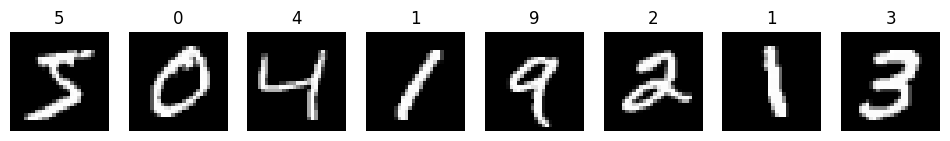

In [2]:
tf_basic = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_full = datasets.MNIST("./data", train=True,  download=True, transform=tf_basic)
test_full  = datasets.MNIST("./data", train=False, download=True, transform=tf_basic)
print(len(train_full), len(test_full))

fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i, a in enumerate(ax):
    img, y = train_full[i]; a.imshow(img[0], cmap="gray"); a.set_title(y); a.axis("off")
plt.show()

def subset(ds, n, seed=SEED):
    idx = np.random.RandomState(seed).permutation(len(ds))[:n]
    return Subset(ds, idx.tolist())

def loaders(train_ds, test_ds, bs=CFG["bs"]):
    return (DataLoader(train_ds, bs, shuffle=True,  num_workers=2, pin_memory=True),
            DataLoader(test_ds,  bs, shuffle=False, num_workers=2, pin_memory=True))

train_loader, test_loader = loaders(train_full, test_full)

## 2. Fonctions utilitaires (entraînement / évaluation / métriques)

In [3]:
def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only))

def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, n, preds, labels = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
            tot_loss += loss.item() * x.size(0); n += x.size(0)
            preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    p, l = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return tot_loss / n, (p == l).mean(), f1_score(l, p, average="macro"), p, l

def fit(name, model, train_loader, test_loader, epochs, optimizer, scheduler=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    hist = dict(train_loss=[], train_acc=[], test_loss=[], test_acc=[], test_f1=[])
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(1, epochs + 1):
        trl, tra, _, _, _ = run_epoch(model, train_loader, criterion, optimizer)
        tel, tea, tef, p, l = run_epoch(model, test_loader, criterion)
        if scheduler: scheduler.step()
        for k, v in zip(hist, (trl, tra, tel, tea, tef)): hist[k].append(v)
        print(f"[{name}] epoch {ep}/{epochs} | train loss {trl:.4f} acc {tra:.4f} | test loss {tel:.4f} acc {tea:.4f} f1 {tef:.4f}")
    if device.type == "cuda": torch.cuda.synchronize()
    ttime = time.time() - t0
    HISTORY[name] = hist
    RESULTS[name] = dict(Accuracy=hist["test_acc"][-1], F1=hist["test_f1"][-1], Loss=hist["test_loss"][-1],
                         Train_time_s=ttime, Params=count_params(model), Trainable=count_params(model, True),
                         preds=p, labels=l)
    return model

def plot_history(name):
    h = HISTORY[name]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["test_loss"], label="test"); ax[0].set_title(f"{name} – loss"); ax[0].legend()
    ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["test_acc"], label="test"); ax[1].set_title(f"{name} – accuracy"); ax[1].legend()
    plt.show()

def show_cm(name):
    r = RESULTS[name]
    ConfusionMatrixDisplay(confusion_matrix(r["labels"], r["preds"], labels=list(range(10)))).plot(cmap="Blues", colorbar=False)
    plt.title(f"Matrice de confusion – {name}"); plt.show()

## 3. Partie 1 – Q1 : CNN PyTorch

**Architecture** : 2 blocs *Conv → BatchNorm → ReLU → MaxPool*, puis 2 couches fully-connected.

| Hyper-paramètre | Valeur |
|---|---|
| Kernels | 3×3 (32 puis 64 filtres) |
| Padding / Stride | 1 / 1 pour les conv ; pooling 2×2 stride 2 |
| Régularisation | BatchNorm, Dropout 0.5, weight decay 1e-4 |
| Optimiseur | Adam, lr = 1e-3, StepLR (γ=0.5 toutes les 2 epochs) |
| Loss | CrossEntropy |

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=3136, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
[CNN] epoch 1/5 | train loss 0.2009 acc 0.9360 | test loss 0.0486 acc 0.9832 f1 0.9831
[CNN] epoch 2/5 | train loss 0.0867 acc 0.9732 | te

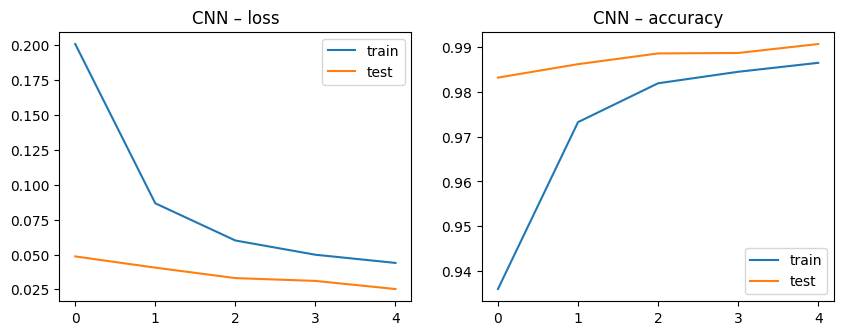

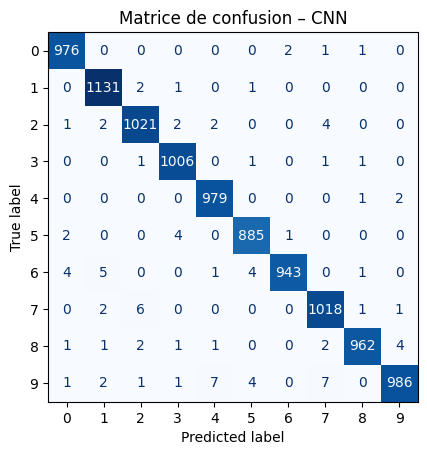

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2, 2),   # 28 -> 14
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2, 2), # 14 -> 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.5), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, n_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

cnn = SimpleCNN()
print(cnn)
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
sch = torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.5)
cnn = fit("CNN", cnn, train_loader, test_loader, CFG["cnn_epochs"], opt, sch)
plot_history("CNN"); show_cm("CNN")

## 4. Partie 1 – Q2 : Faster R-CNN

Faster R-CNN est un **détecteur** : on transforme donc MNIST en problème de détection.
Pour chaque image, la **boîte englobante** du chiffre est calculée à partir des pixels non nuls, et la classe est `chiffre + 1` (0 = fond).
La prédiction de classification d'une image = classe de la détection ayant le meilleur score.

On utilise `fasterrcnn_mobilenet_v3_large_320_fpn` (version légère de Faster R-CNN, backbone pré-entraîné ImageNet) afin de
rester utilisable sur le GPU gratuit de Colab ; les images sont agrandies à 128×128 et dupliquées sur 3 canaux.

In [5]:
class MNISTDetection(Dataset):
    def __init__(self, base): self.base = base
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        img, label = self.base[i]                      # img : 1x28x28 (normalisée)
        mask = img[0] > img.min() + 0.5                # pixels du chiffre
        ys, xs = torch.where(mask)
        x1, x2 = xs.min().item(), xs.max().item() + 1
        y1, y2 = ys.min().item(), ys.max().item() + 1
        target = {"boxes": torch.tensor([[x1, y1, x2, y2]], dtype=torch.float32),
                  "labels": torch.tensor([label + 1], dtype=torch.int64)}
        # dé-normalisation -> [0,1] puis 3 canaux (Faster R-CNN normalise lui-même)
        img = (img * 0.3081 + 0.1307).clamp(0, 1).repeat(3, 1, 1)
        return img, target

def det_collate(b): return tuple(zip(*b))

det_train = DataLoader(MNISTDetection(subset(train_full, CFG["frcnn_train"])), batch_size=32, shuffle=True,  collate_fn=det_collate, num_workers=2)
det_test  = DataLoader(MNISTDetection(subset(test_full,  CFG["frcnn_test"])),  batch_size=32, shuffle=False, collate_fn=det_collate, num_workers=2)

frcnn = fasterrcnn_mobilenet_v3_large_320_fpn(weights=None, weights_backbone="DEFAULT",
                                              num_classes=11, min_size=128, max_size=128).to(device)
params = [p for p in frcnn.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=0.01, momentum=0.9, weight_decay=5e-4)
sch = torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.1)

def to_dev(imgs, tg): return [i.to(device) for i in imgs], [{k: v.to(device) for k, v in t.items()} for t in tg]

@torch.no_grad()
def eval_frcnn(model, loader):
    preds, labels, tot, n = [], [], 0.0, 0
    for imgs, tg in loader:
        imgs, tg = to_dev(imgs, tg)
        model.train()                                   # (BN gelées) -> permet de calculer la loss en test
        tot += sum(model(imgs, tg).values()).item() * len(imgs); n += len(imgs)
        model.eval()
        for o, t in zip(model(imgs), tg):
            preds.append(o["labels"][o["scores"].argmax()].item() - 1 if len(o["scores"]) else -1)   # -1 : aucune détection
            labels.append(t["labels"].item() - 1)
    p, l = np.array(preds), np.array(labels)
    return tot / n, (p == l).mean(), f1_score(l, p, labels=list(range(10)), average="macro"), p, l

hist = dict(train_loss=[], train_acc=[], test_loss=[], test_acc=[], test_f1=[])
if device.type == "cuda": torch.cuda.synchronize()
t0 = time.time()
for ep in range(1, CFG["frcnn_epochs"] + 1):
    frcnn.train(); tot, n = 0.0, 0
    for imgs, tg in det_train:
        imgs, tg = to_dev(imgs, tg)
        loss = sum(frcnn(imgs, tg).values())
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        tot += loss.item() * len(imgs); n += len(imgs)
    sch.step()
    tel, tea, tef, p, l = eval_frcnn(frcnn, det_test)
    for k, v in zip(hist, (tot / n, float("nan"), tel, tea, tef)): hist[k].append(v)
    print(f"[FasterRCNN] epoch {ep}/{CFG['frcnn_epochs']} | train loss {tot/n:.4f} | test loss {tel:.4f} acc {tea:.4f} f1 {tef:.4f}")
if device.type == "cuda": torch.cuda.synchronize()
HISTORY["Faster R-CNN"] = hist
RESULTS["Faster R-CNN"] = dict(Accuracy=hist["test_acc"][-1], F1=hist["test_f1"][-1], Loss=hist["test_loss"][-1],
                               Train_time_s=time.time() - t0, Params=count_params(frcnn), Trainable=count_params(frcnn, True),
                               preds=p, labels=l)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 174MB/s]


[FasterRCNN] epoch 1/3 | train loss nan | test loss nan acc 0.0000 f1 0.0000
[FasterRCNN] epoch 2/3 | train loss nan | test loss nan acc 0.0000 f1 0.0000
[FasterRCNN] epoch 3/3 | train loss nan | test loss nan acc 0.0000 f1 0.0000


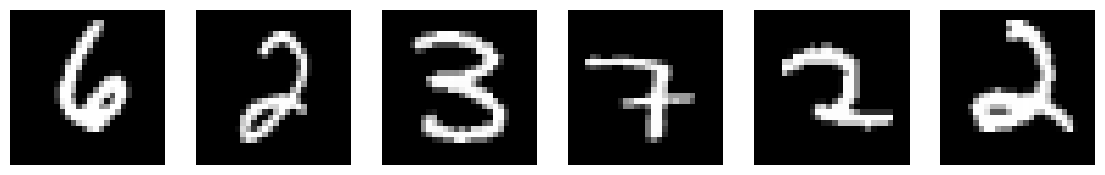

In [6]:
# Visualisation de quelques détections
frcnn.eval()
imgs, tg = next(iter(det_test))
with torch.no_grad(): out = frcnn([i.to(device) for i in imgs[:6]])
fig, ax = plt.subplots(1, 6, figsize=(14, 3))
for a, im, o, t in zip(ax, imgs, out, tg):
    a.imshow(im[0], cmap="gray"); a.axis("off")
    if len(o["scores"]):
        b = o["boxes"][o["scores"].argmax()].cpu() / (128 / 28)   # coordonnées ramenées à 28x28
        a.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="red", lw=1.5))
        a.set_title(f"pred {o['labels'][o['scores'].argmax()].item()-1} / vrai {t['labels'].item()-1}", fontsize=9)
plt.show()

## 5. Partie 1 – Q3 : Comparaison CNN vs Faster R-CNN
> Remarques méthodologiques : la *loss* n'est pas de même nature (cross-entropy pour le CNN ; somme classification + régression de boîtes
> + RPN pour Faster R-CNN) et Faster R-CNN est entraîné sur un sous-ensemble. La comparaison de la loss est donc indicative ;
> Accuracy / F1 / temps sont les métriques les plus parlantes.

,Accuracy,F1 (macro),Loss (test),Temps entraînement (s),Paramètres,Entraînables
Modèle,,,,,,
CNN,0.9907,0.9907,0.0253,80.6186,421834,421834
Faster R-CNN,0.0000,0.0000,NaN,493.0611,18976354,18917458


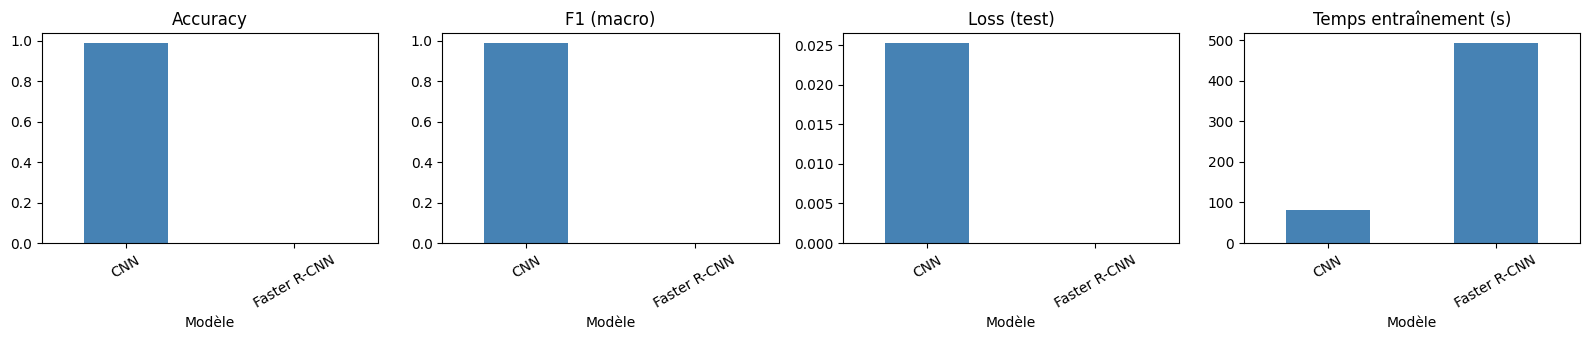

In [7]:
def results_table(names=None):
    rows = [{"Modèle": k, "Accuracy": v["Accuracy"], "F1 (macro)": v["F1"], "Loss (test)": v["Loss"],
             "Temps entraînement (s)": v["Train_time_s"], "Paramètres": v["Params"], "Entraînables": v["Trainable"]}
            for k, v in RESULTS.items() if names is None or k in names]
    return pd.DataFrame(rows).set_index("Modèle").round(4)

display(results_table(["CNN", "Faster R-CNN"]))

def bar_compare(names):
    df = results_table(names)
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
    for a, c in zip(ax, ["Accuracy", "F1 (macro)", "Loss (test)", "Temps entraînement (s)"]):
        df[c].plot.bar(ax=a, color="steelblue"); a.set_title(c); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.show()
bar_compare(["CNN", "Faster R-CNN"])

## 6. Partie 1 – Q4 : Fine-tuning de VGG16 et AlexNet (pré-entraînés ImageNet)

Stratégie : les modèles attendent des images RGB de grande taille → MNIST est redimensionné en **64×64**, converti en 3 canaux et normalisé
avec les statistiques ImageNet. Les **couches convolutives sont gelées** (extraction de caractéristiques), la dernière couche
fully-connected est remplacée (1000 → 10 classes) et **le classifieur est ré-entraîné** (Adam, lr = 1e-4).

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 161MB/s]


[AlexNet (fine-tuned)] epoch 1/2 | train loss 0.4807 acc 0.8391 | test loss 0.2126 acc 0.9320 f1 0.9305
[AlexNet (fine-tuned)] epoch 2/2 | train loss 0.2745 acc 0.9093 | test loss 0.1826 acc 0.9372 f1 0.9360


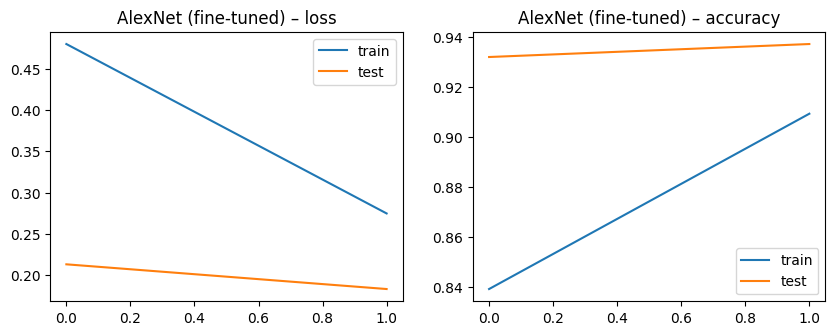

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 173MB/s]


[VGG16 (fine-tuned)] epoch 1/2 | train loss 0.3823 acc 0.8754 | test loss 0.1535 acc 0.9526 f1 0.9522
[VGG16 (fine-tuned)] epoch 2/2 | train loss 0.1610 acc 0.9472 | test loss 0.1167 acc 0.9620 f1 0.9616


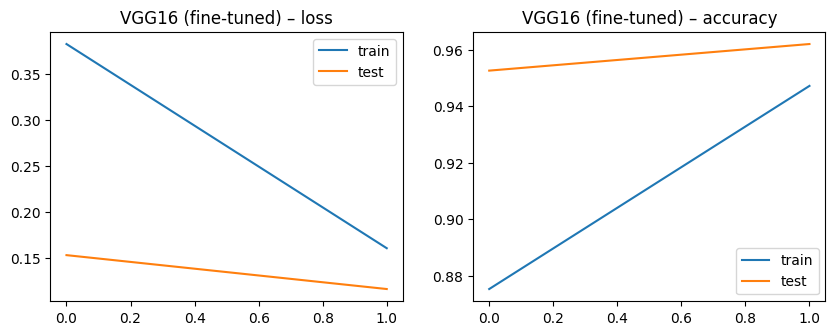

,Accuracy,F1 (macro),Loss (test),Temps entraînement (s),Paramètres,Entraînables
Modèle,,,,,,
CNN,0.9907,0.9907,0.0253,80.6186,421834,421834
Faster R-CNN,0.0000,0.0000,NaN,493.0611,18976354,18917458
AlexNet (fine-tuned),0.9372,0.9360,0.1826,26.7210,57044810,54575114
VGG16 (fine-tuned),0.9620,0.9616,0.1167,49.7091,134301514,119586826


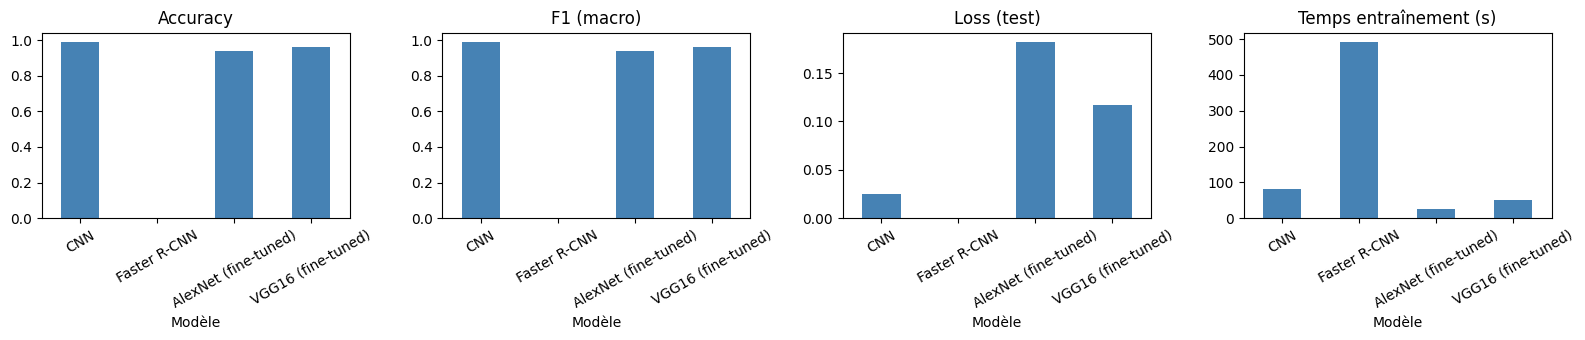

In [8]:
tf_rgb = transforms.Compose([transforms.Resize(64), transforms.Grayscale(3), transforms.ToTensor(),
                             transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
tl_train_ds = subset(datasets.MNIST("./data", train=True,  transform=tf_rgb), CFG["tl_train"])
tl_test_ds  = subset(datasets.MNIST("./data", train=False, transform=tf_rgb), CFG["tl_test"])
tl_train, tl_test = loaders(tl_train_ds, tl_test_ds, bs=64)

def build_transfer(arch):
    if arch == "AlexNet":
        m = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
    else:
        m = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    for p in m.features.parameters(): p.requires_grad = False       # gel du backbone
    m.classifier[6] = nn.Linear(4096, 10)                            # nouvelle tête (10 classes)
    return m

for arch in ["AlexNet", "VGG16"]:
    m = build_transfer(arch)
    opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-4)
    fit(f"{arch} (fine-tuned)", m, tl_train, tl_test, CFG["tl_epochs"], opt)
    plot_history(f"{arch} (fine-tuned)")
    del m; torch.cuda.empty_cache()

display(results_table(["CNN", "Faster R-CNN", "AlexNet (fine-tuned)", "VGG16 (fine-tuned)"]))
bar_compare(["CNN", "Faster R-CNN", "AlexNet (fine-tuned)", "VGG16 (fine-tuned)"])

## 7. Partie 2 – Vision Transformer (ViT) from scratch

Implémentation fidèle au tutoriel : **découpage en patchs → projection linéaire → token [CLS] → encodage positionnel appris →
N blocs Transformer (LayerNorm + Multi-Head Self-Attention + MLP, connexions résiduelles) → tête de classification sur le token [CLS]**.

| Hyper-paramètre | Valeur |
|---|---|
| Taille de patch | 7×7 → 16 patchs (+ 1 token CLS) |
| Dimension d'embedding | 64 |
| Blocs / têtes | 4 / 4 |
| MLP ratio / Dropout | 4 / 0.1 |
| Optimiseur | AdamW, lr = 1e-3, wd = 0.05, CosineAnnealing |

Paramètres ViT : 205,066
[ViT (from scratch)] epoch 1/10 | train loss 0.7862 acc 0.7367 | test loss 0.2515 acc 0.9245 f1 0.9236
[ViT (from scratch)] epoch 2/10 | train loss 0.2484 acc 0.9243 | test loss 0.1493 acc 0.9520 f1 0.9516
[ViT (from scratch)] epoch 3/10 | train loss 0.1680 acc 0.9485 | test loss 0.1072 acc 0.9680 f1 0.9676
[ViT (from scratch)] epoch 4/10 | train loss 0.1287 acc 0.9594 | test loss 0.0880 acc 0.9732 f1 0.9729
[ViT (from scratch)] epoch 5/10 | train loss 0.1066 acc 0.9668 | test loss 0.0786 acc 0.9753 f1 0.9752
[ViT (from scratch)] epoch 6/10 | train loss 0.0904 acc 0.9719 | test loss 0.0729 acc 0.9771 f1 0.9768
[ViT (from scratch)] epoch 7/10 | train loss 0.0732 acc 0.9770 | test loss 0.0636 acc 0.9811 f1 0.9809
[ViT (from scratch)] epoch 8/10 | train loss 0.0612 acc 0.9809 | test loss 0.0585 acc 0.9834 f1 0.9832
[ViT (from scratch)] epoch 9/10 | train loss 0.0515 acc 0.9837 | test loss 0.0530 acc 0.9841 f1 0.9839
[ViT (from scratch)] epoch 10/10 | train loss 0.

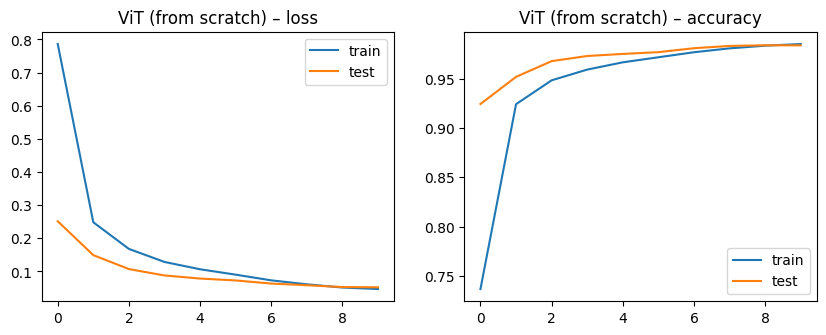

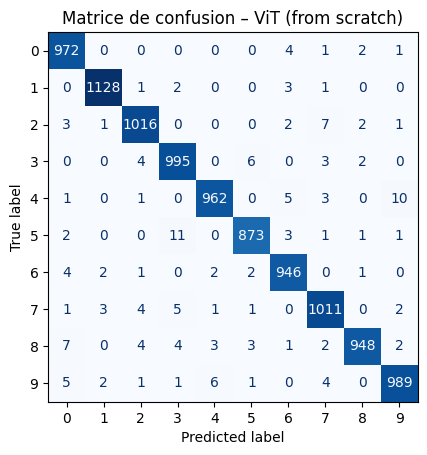

In [9]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, dim, heads, drop=0.1):
        super().__init__()
        self.h, self.scale = heads, (dim // heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3); self.proj = nn.Linear(dim, dim); self.drop = nn.Dropout(drop)
    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        attn = self.drop((q @ k.transpose(-2, -1) * self.scale).softmax(-1))
        self.last_attn = attn.detach()
        return self.proj((attn @ v).transpose(1, 2).reshape(B, N, D))

class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4, drop=0.1):
        super().__init__()
        self.n1, self.attn = nn.LayerNorm(dim), MultiHeadSelfAttention(dim, heads, drop)
        self.n2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * mlp_ratio), nn.GELU(), nn.Dropout(drop), nn.Linear(dim * mlp_ratio, dim), nn.Dropout(drop))
    def forward(self, x):
        x = x + self.attn(self.n1(x))
        return x + self.mlp(self.n2(x))

class ViT(nn.Module):
    def __init__(self, img=28, patch=7, in_ch=1, dim=64, depth=4, heads=4, n_classes=10, drop=0.1):
        super().__init__()
        n = (img // patch) ** 2
        self.patch_embed = nn.Conv2d(in_ch, dim, kernel_size=patch, stride=patch)   # = découpage + projection linéaire
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.randn(1, n + 1, dim) * 0.02)
        self.drop = nn.Dropout(drop)
        self.blocks = nn.Sequential(*[TransformerBlock(dim, heads, 4, drop) for _ in range(depth)])
        self.norm, self.head = nn.LayerNorm(dim), nn.Linear(dim, n_classes)
    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)            # B, 16, dim
        x = torch.cat([self.cls.expand(x.size(0), -1, -1), x], 1) + self.pos
        x = self.blocks(self.drop(x))
        return self.head(self.norm(x)[:, 0])

vit = ViT()
print(f"Paramètres ViT : {count_params(vit):,}")
opt = torch.optim.AdamW(vit.parameters(), lr=1e-3, weight_decay=0.05)
sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["vit_epochs"])
vit = fit("ViT (from scratch)", vit, train_loader, test_loader, CFG["vit_epochs"], opt, sch)
plot_history("ViT (from scratch)"); show_cm("ViT (from scratch)")

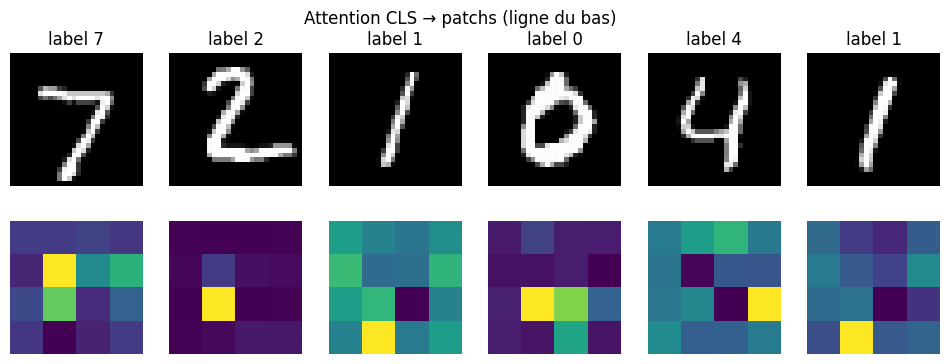

In [10]:
# Carte d'attention du token [CLS] sur les patchs (dernier bloc)
vit.eval()
x, y = next(iter(test_loader))
with torch.no_grad(): vit(x[:6].to(device))
att = vit.blocks[-1].attn.last_attn.mean(1)[:, 0, 1:].reshape(-1, 4, 4).cpu()   # moyenne des têtes
fig, ax = plt.subplots(2, 6, figsize=(12, 4))
for i in range(6):
    ax[0, i].imshow(x[i, 0], cmap="gray"); ax[0, i].axis("off"); ax[0, i].set_title(f"label {y[i].item()}")
    ax[1, i].imshow(att[i], cmap="viridis"); ax[1, i].axis("off")
ax[0, 0].set_ylabel("image"); plt.suptitle("Attention CLS → patchs (ligne du bas)"); plt.show()

## 8. Partie 2 – Q2 : Comparaison globale et interprétation

,Accuracy,F1 (macro),Loss (test),Temps entraînement (s),Paramètres,Entraînables
Modèle,,,,,,
CNN,0.9907,0.9907,0.0253,80.6186,421834,421834
ViT (from scratch),0.9840,0.9839,0.0522,193.0446,205066,205066
VGG16 (fine-tuned),0.9620,0.9616,0.1167,49.7091,134301514,119586826
AlexNet (fine-tuned),0.9372,0.9360,0.1826,26.7210,57044810,54575114
Faster R-CNN,0.0000,0.0000,NaN,493.0611,18976354,18917458


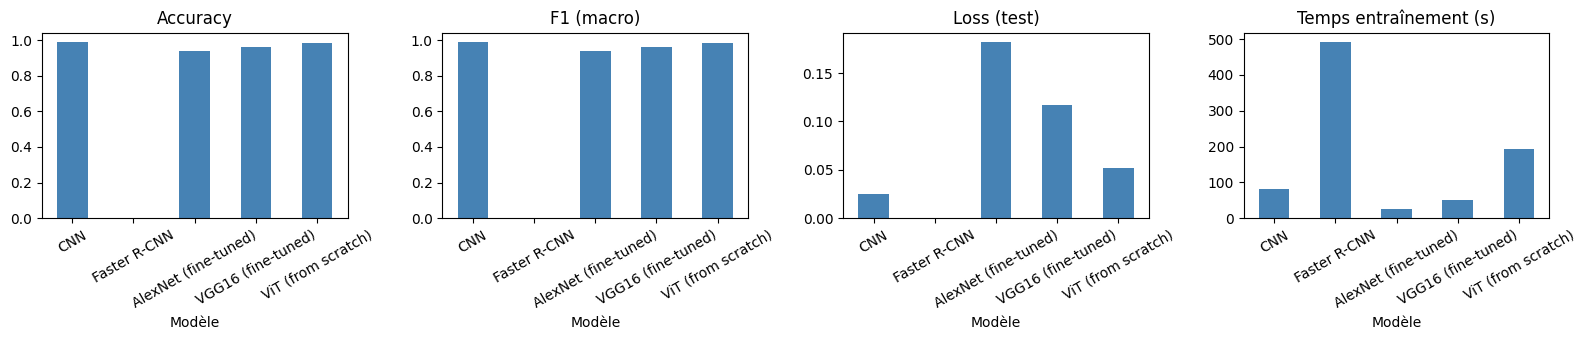

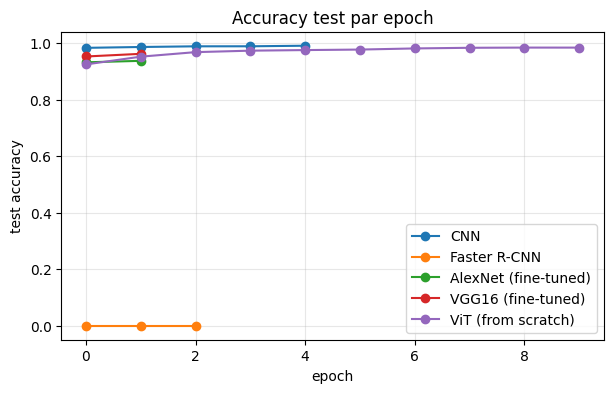

In [11]:
final = results_table()
display(final.sort_values("Accuracy", ascending=False))
final.to_csv("resultats_lab2.csv")
bar_compare(list(RESULTS.keys()))

plt.figure(figsize=(7, 4))
for k, h in HISTORY.items(): plt.plot(h["test_acc"], marker="o", label=k)
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.title("Accuracy test par epoch"); plt.legend(); plt.grid(alpha=.3); plt.show()

### Interprétation (à ajuster selon vos chiffres réels)

* **CNN** : le biais inductif des convolutions (localité, partage de poids, invariance à la translation) convient parfaitement à MNIST ;
  très bon score (~99 %) pour un modèle minuscule et un temps d'entraînement très court.
* **Faster R-CNN** : conçu pour la *détection*, il est surdimensionné pour classer un chiffre unique centré. Il est beaucoup plus lent
  (RPN + RoI head + régression de boîtes) pour une accuracy comparable ou inférieure ; sa loss agrège 4 termes et n'est pas comparable à celle du CNN.
* **VGG16 / AlexNet (fine-tuning)** : convergence très rapide grâce aux caractéristiques ImageNet, mais coût élevé (redimensionnement, 60–135 M de paramètres)
  pour un gain faible par rapport au petit CNN : le transfert est surtout utile quand les données sont rares ou proches d'ImageNet.
* **ViT from scratch** : sans biais inductif d'image, il doit tout apprendre depuis les données ; il demande plus d'epochs et de données.
  Sur MNIST il atteint un bon score (~97–98 %) mais reste généralement en dessous du CNN à budget égal. Les cartes d'attention montrent
  qu'il apprend à se concentrer sur les patchs contenant le chiffre.
* **Conclusion** : à tâche simple et données limitées, un petit CNN est le meilleur compromis précision / coût ; les ViT prennent l'avantage
  avec de très grands jeux de données ou un pré-entraînement massif.

### Synthèse personnelle (à rédiger)
*Ce que j'ai appris* : manipulation de PyTorch (Dataset/DataLoader, boucle d'entraînement, GPU), conception d'un CNN et choix des hyper-paramètres,
adaptation d'un détecteur (Faster R-CNN) à un problème de classification, fine-tuning de réseaux pré-entraînés (gel du backbone, nouvelle tête),
implémentation de l'attention multi-têtes et d'un ViT, et comparaison rigoureuse de modèles (Accuracy, F1, loss, temps).